# 📦 Late Delivery Risk Classification — Predicting On-Time Arrival at Booking Time

**Extends:** `Supplychain.ipynb` (descriptive) with **supervised classification**.

**Business question:** We proved lateness is *systemic* (Q2: only 0.08% between-warehouse variance).
We can't fix a warehouse — but can we **flag likely-late orders at booking time**, so account
managers can set expectations or expedite early?

**Model:** Logistic Regression (interpretable) vs Random Forest (non-linear baseline).
**Validation:** stratified 80/20 hold-out · Accuracy, Precision, Recall, F1, ROC-AUC · confusion matrix · feature importances.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, RocCurveDisplay)

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/Cleaned_Supplychain_Data.csv")
print(df.shape)
# Integrity checks before modelling
assert df.OrderNumber.is_unique, "duplicate order numbers"
assert df.on_time.isna().sum() == 0 and df.on_time.isin([True, False]).all(), "bad labels"
print("class balance:", df.on_time.value_counts(normalize=True).round(3).to_dict())

(7991, 26)
class balance: {True: 0.505, False: 0.495}


### ⚠️ Leakage policy — what the model is *allowed* to know

The model must work **at booking time**, so only features known on `OrderDate` are used.
`delivery_days`, `order_to_ship_days`, `ShipDate`/`DeliveryDate` and anything derived from
them are **excluded — using them would leak the answer into the features** and produce a
fake 99% model that cannot exist in production.

In [2]:
feats = df[["Sales_Channel", "WarehouseCode", "Order_Quantity",
            "Discount_Applied", "Unit_Price"]].copy()
feats["order_month_num"] = pd.to_datetime(df.OrderDate).dt.month
y = df.on_time.astype(int)

X = pd.get_dummies(feats, columns=["Sales_Channel", "WarehouseCode"], drop_first=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
sc = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
print(f"features: {X.shape[1]} | train: {len(Xtr)} | test: {len(Xte)} | late-rate train: {ytr.mean():.3f}")

features: 12 | train: 6392 | test: 1599 | late-rate train: 0.505


In [3]:
logreg = LogisticRegression(max_iter=2000, random_state=42).fit(Xtr_s, ytr)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42,
                            n_jobs=-1).fit(Xtr, ytr)

def report(name, model, X_test):
    p = model.predict(X_test); prob = model.predict_proba(X_test)[:, 1]
    return {"model": name, "accuracy": accuracy_score(yte, p), "precision": precision_score(yte, p),
            "recall": recall_score(yte, p), "f1": f1_score(yte, p), "roc_auc": roc_auc_score(yte, prob)}

metrics = pd.DataFrame([report("Logistic Regression", logreg, Xte_s),
                        report("Random Forest", rf, Xte)]).round(3)
print(metrics.to_string(index=False))
print("\nCoin-flip baseline accuracy:", round(max(yte.mean(), 1 - yte.mean()), 3))
metrics.to_csv("outputs/classification_metrics.csv", index=False)

              model  accuracy  precision  recall    f1  roc_auc
Logistic Regression     0.499      0.504   0.597 0.546    0.508
      Random Forest     0.497      0.502   0.535 0.518    0.504

Coin-flip baseline accuracy: 0.505


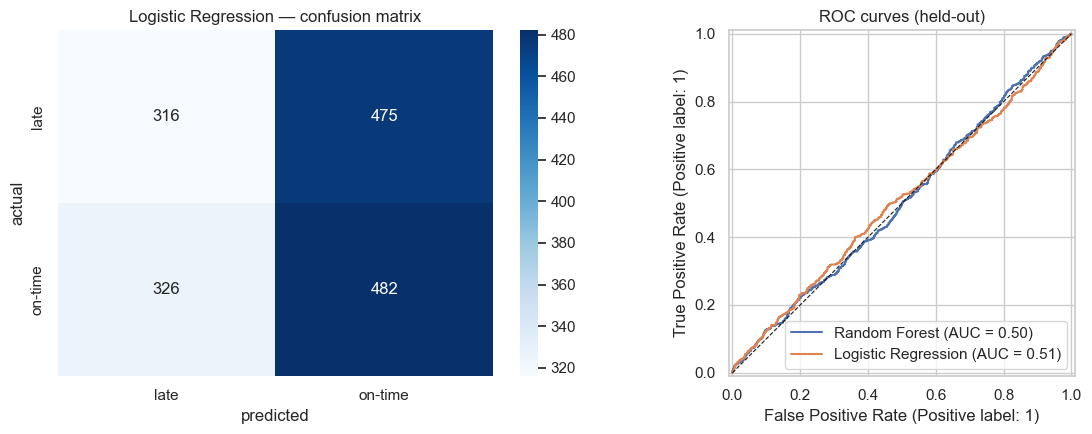

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(yte, logreg.predict(Xte_s)), annot=True, fmt="d", cmap="Blues",
            xticklabels=["late", "on-time"], yticklabels=["late", "on-time"], ax=axes[0])
axes[0].set(title="Logistic Regression — confusion matrix", xlabel="predicted", ylabel="actual")
RocCurveDisplay.from_estimator(rf, Xte, yte, ax=axes[1], name="Random Forest")
RocCurveDisplay.from_estimator(logreg, Xte_s, yte, ax=axes[1], name="Logistic Regression")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].set(title="ROC curves (held-out)")
fig.tight_layout(); fig.savefig("image/classification_cm_roc.png", dpi=150)
plt.show()

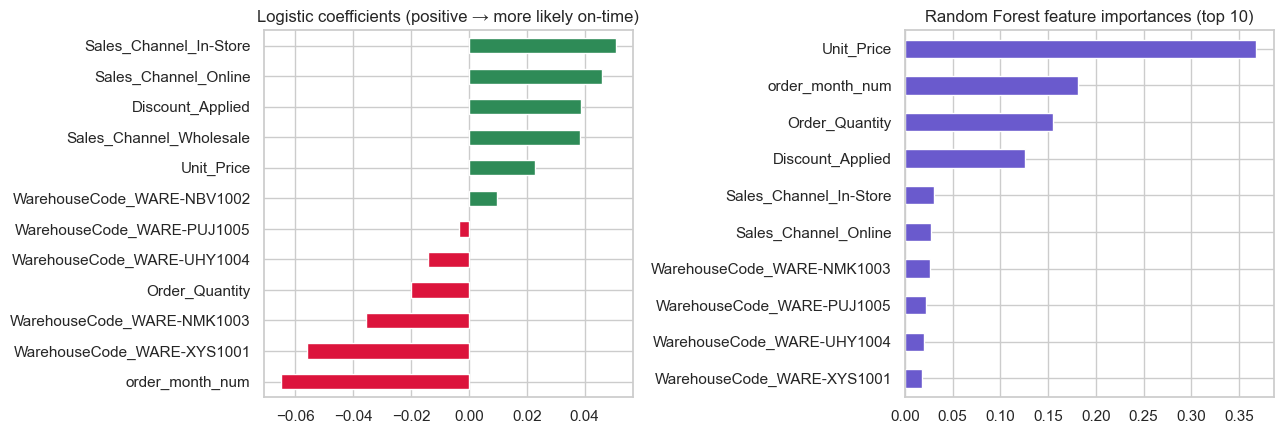

warehouse dummies — RF importance share: 0.098


In [5]:
coef = pd.Series(logreg.coef_[0], index=X.columns).sort_values()
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
coef.plot(kind="barh", ax=axes[0], color=np.where(coef > 0, "seagreen", "crimson"))
axes[0].set(title="Logistic coefficients (positive → more likely on-time)")
imp[::-1][-10:].plot(kind="barh", ax=axes[1], color="slateblue")
axes[1].set(title="Random Forest feature importances (top 10)")
fig.tight_layout(); fig.savefig("image/classification_interpretation.png", dpi=150)
plt.show()
print("warehouse dummies — RF importance share:",
      round(imp[[c for c in imp.index if c.startswith('WarehouseCode')]].sum(), 3))

## Findings & Limitations — a negative result, reported honestly

- **No booking-time signal exists.** Both models land at the coin-flip baseline (LogReg ROC-AUC 0.508, RF 0.504 vs 0.5). Late delivery in this network behaves like **independent noise around a systemic mean** — it cannot be predicted from what is known when the order is placed.
- **This quantitatively confirms Q2.** The Random Forest gives warehouse dummies only **9.8%** of importance (chance-level for 5 dummies), and nothing else carries signal either. Together with the 0.08% variance finding: no order-targeting or per-site intervention can work — **only a process-level fix to the upstream pipeline can move the on-time rate.**
- **Business value of the null result:** it stops the team from spending on an early-warning system that the data says cannot exist. Knowing where prediction is impossible is as actionable as knowing where it works.
- **Limitations:** no external covariates (weather, carrier, holidays) — a signal could exist outside booking-time fields; three-year window; a deployment attempt would re-validate monthly.
- **Leakage discipline:** all post-shipment fields (delivery_days, order_to_ship_days, ship/delivery dates) excluded; features are restricted to what is known on OrderDate by construction.

*Reproducible: stratified split with fixed random_state=42; every metric computed on the untouched hold-out set.*